# Simple Exponential Smoothing (SES)

## Learning objectives
- Understand the intuition and equations behind SES.
- Implement SES manually using Python.
- Fit SES with `statsmodels`.
- Explore the smoothing parameter alpha.
- Evaluate forecasts with a chronological train-test split.
- Generate future forecasts and inspect residuals.

## 1. Introduction

**Simple Exponential Smoothing (SES)** is a statistical forecasting method for a time series with a relatively stable level and no clear trend or seasonality.

It combines the latest observation with the previous smoothed level. Recent observations receive more weight, while older observations have progressively less influence.

SES is useful for stable demand, such as a product whose monthly consumption fluctuates around a consistent average. If the data has a trend, consider Holt's method; if it has seasonality, consider Holt-Winters.

Libraries: NumPy, pandas, Matplotlib, scikit-learn and statsmodels.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Generate synthetic monthly demand

We simulate a product whose demand fluctuates around a stable level. The data is synthetic and has no systematic trend or repeating seasonal pattern.

In [2]:
n_periods = 120
dates = pd.date_range("2016-01-01", periods=n_periods, freq="MS")
base_level = 500
noise = np.random.normal(0, 35, n_periods)
values = np.maximum(0, np.round(base_level + noise)).astype(int)
demand = pd.Series(values, index=dates, name="Demand")

display(demand.to_frame().head(10))
print("Observations:", len(demand))
print("Mean demand:", round(demand.mean(), 2))
print("Standard deviation:", round(demand.std(), 2))

,Demand
2016-01-01,517
2016-02-01,495
2016-03-01,523
2016-04-01,553
2016-05-01,492
2016-06-01,492
2016-07-01,555
2016-08-01,527
2016-09-01,484
2016-10-01,519


Observations: 120
Mean demand: 497.2
Standard deviation: 32.39


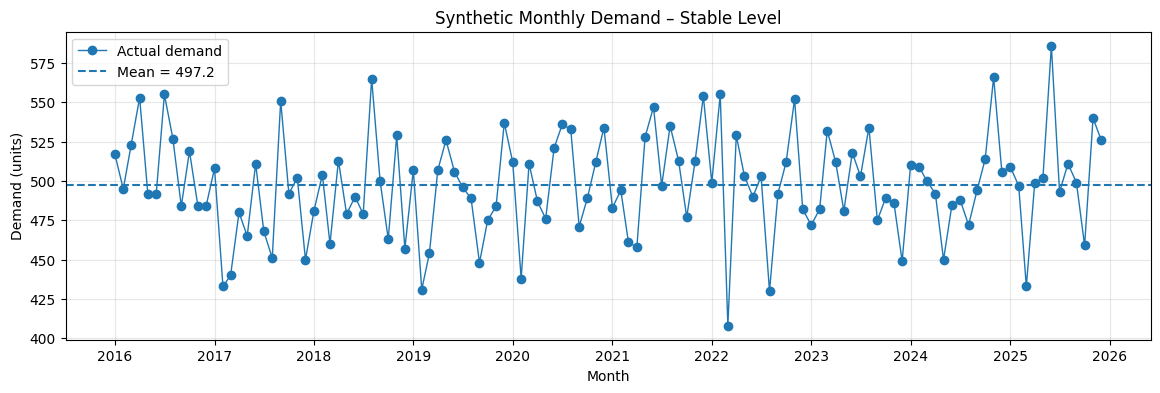

In [3]:
plt.figure(figsize=(14, 4))
plt.plot(demand.index, demand.values, marker="o", linewidth=1, label="Actual demand")
plt.axhline(demand.mean(), linestyle="--", label=f"Mean = {demand.mean():.1f}")
plt.title("Synthetic Monthly Demand – Stable Level")
plt.xlabel("Month"); plt.ylabel("Demand (units)")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 3. SES equations

SES maintains one component: the **level**.

### Level update equation

$$
L_t = \\alpha Y_t + (1-\\alpha)L_{t-1}
$$

### Forecast equation

$$
\\hat{Y}_{t+h|t} = L_t
$$

Where:
- $Y_t$ = actual observation at time $t$
- $L_t$ = estimated level after observing period $t$
- $L_{t-1}$ = previous estimated level
- $\\alpha$ = smoothing parameter between 0 and 1
- $h$ = forecast horizon

The next-period forecast is the latest estimated level. All future point forecasts are equal because basic SES does not model trend or seasonality.

**Alpha intuition**
- Low alpha: more weight on the previous level; smoother, slower response.
- High alpha: more weight on the latest observation; faster response, but potentially more sensitive to noise.
- Alpha = 1: the updated level equals the latest actual, similar to a Naive one-step forecast.
- Alpha near 0: the level changes slowly.

Alpha can be selected using a validation set or estimated by model fitting.

## 4. Manual worked example

Suppose demand is `[100, 110, 105, 115, 120]`, the initial level is 100, and alpha is 0.30.

Second observation:

$$
L_2 = 0.30(110) + 0.70(100) = 103
$$

Third observation:

$$
L_3 = 0.30(105) + 0.70(103) = 103.6
$$

Continue this update for each observation. The final updated level becomes the forecast for all future horizons.

In [4]:
example_values = [100, 110, 105, 115, 120]
alpha = 0.30
level = float(example_values[0])
rows = [{"Period": 1, "Actual": example_values[0],
         "Forecast_before_actual": np.nan, "Updated_level": level}]

for t in range(1, len(example_values)):
    forecast = level
    actual = float(example_values[t])
    level = alpha * actual + (1 - alpha) * level
    rows.append({"Period": t + 1, "Actual": actual,
                 "Forecast_before_actual": forecast, "Updated_level": level})

display(pd.DataFrame(rows))
print("Next-period forecast:", round(level, 3))

,Period,Actual,Forecast_before_actual,Updated_level
0,1,100.000,NaN,100.000
1,2,110.000,100.000,103.000
2,3,105.000,103.000,103.600
3,4,115.000,103.600,107.020
4,5,120.000,107.020,110.914


Next-period forecast: 110.914


## 5. Implement SES from scratch

The function records each one-step-ahead forecast **before** using that period's actual observation to update the level. This prevents future information from leaking into the fitted forecast.

Initialization: the first observation is used as the initial level. Since there is no earlier level, the first fitted forecast is left as `NaN`.

In [5]:
def ses_manual(y, alpha, initial_level=None):
    y = pd.Series(y, dtype=float)
    if y.empty:
        raise ValueError("Input series must not be empty.")
    if not 0 <= alpha <= 1:
        raise ValueError("Alpha must be between 0 and 1.")

    level = float(y.iloc[0]) if initial_level is None else float(initial_level)
    fitted = pd.Series(np.nan, index=y.index, dtype=float, name="SES_Fitted")
    levels = pd.Series(np.nan, index=y.index, dtype=float, name="SES_Level")
    levels.iloc[0] = level

    for t in range(1, len(y)):
        fitted.iloc[t] = level              # forecast before observing y[t]
        level = alpha * float(y.iloc[t]) + (1-alpha) * level
        levels.iloc[t] = level              # update after observing y[t]

    return fitted, levels, level


manual_fitted, manual_levels, final_level = ses_manual(demand, alpha=0.30)
manual_results = pd.DataFrame({
    "Actual": demand,
    "Fitted_Forecast": manual_fitted,
    "Updated_Level": manual_levels
})
display(manual_results.head(12))
print("Final smoothed level:", round(final_level, 3))

,Actual,Fitted_Forecast,Updated_Level
2016-01-01,517,NaN,517.000
2016-02-01,495,517.000,510.400
2016-03-01,523,510.400,514.180
2016-04-01,553,514.180,525.826
2016-05-01,492,525.826,515.678
2016-06-01,492,515.678,508.575
2016-07-01,555,508.575,522.502
2016-08-01,527,522.502,523.852
2016-09-01,484,523.852,511.896
2016-10-01,519,511.896,514.027


Final smoothed level: 512.966


## 6. Plot fitted forecasts

The fitted value at each period is the level estimated using information available before that period's actual demand was observed.

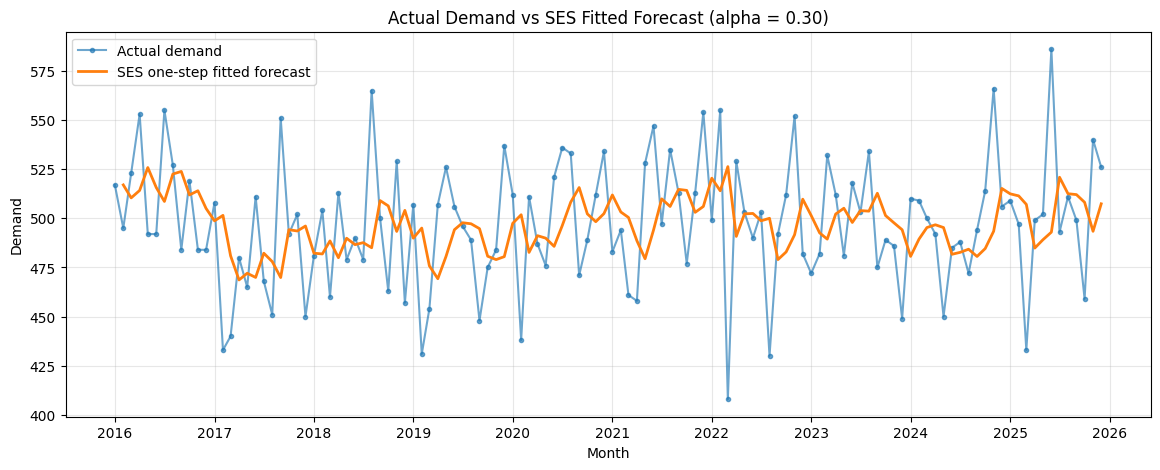

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(demand.index, demand.values, label="Actual demand", alpha=.65, marker="o", markersize=3)
plt.plot(manual_fitted.index, manual_fitted.values, label="SES one-step fitted forecast", linewidth=2)
plt.title("Actual Demand vs SES Fitted Forecast (alpha = 0.30)")
plt.xlabel("Month"); plt.ylabel("Demand")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 7. Explore different alpha values

A low alpha produces a smoother estimate. A high alpha allows the forecast to react more quickly to recent observations.

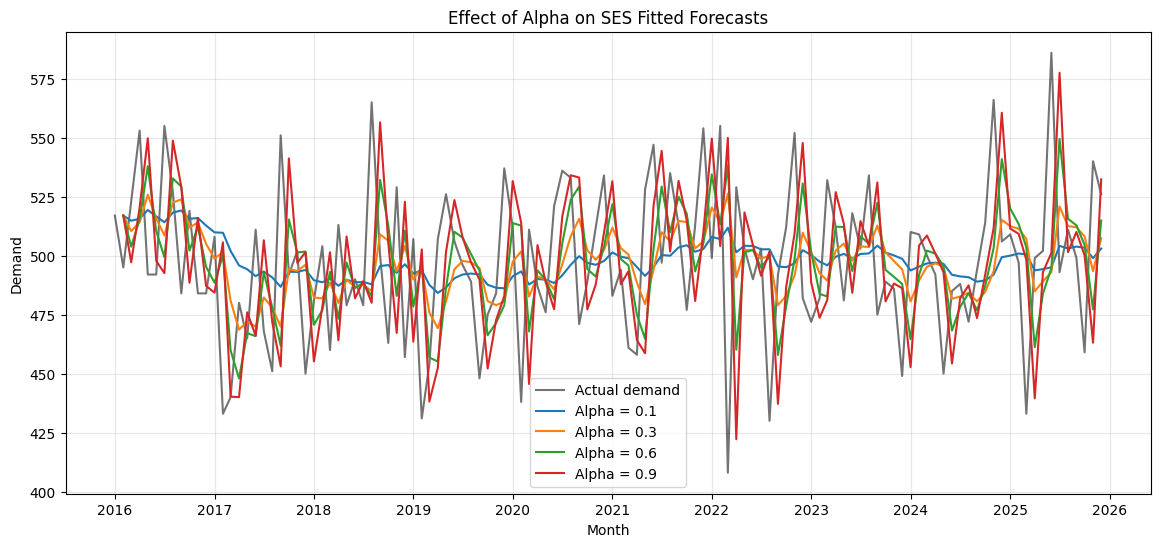

In [7]:
alpha_values = [0.10, 0.30, 0.60, 0.90]
fitted_by_alpha = {}
for a in alpha_values:
    fitted, levels, final = ses_manual(demand, alpha=a)
    fitted_by_alpha[a] = fitted

plt.figure(figsize=(14, 6))
plt.plot(demand.index, demand.values, label="Actual demand", color="black", alpha=.55)
for a, fitted in fitted_by_alpha.items():
    plt.plot(fitted.index, fitted.values, label=f"Alpha = {a}")
plt.title("Effect of Alpha on SES Fitted Forecasts")
plt.xlabel("Month"); plt.ylabel("Demand")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 8. Chronological train-test split

Use the first 80% for training and the final 20% for testing. Preserve time order and do not use test actuals when fitting the model.

Training observations: 96 | Testing observations: 24
Training: 2016-01-01 to 2023-12-01
Testing: 2024-01-01 to 2025-12-01


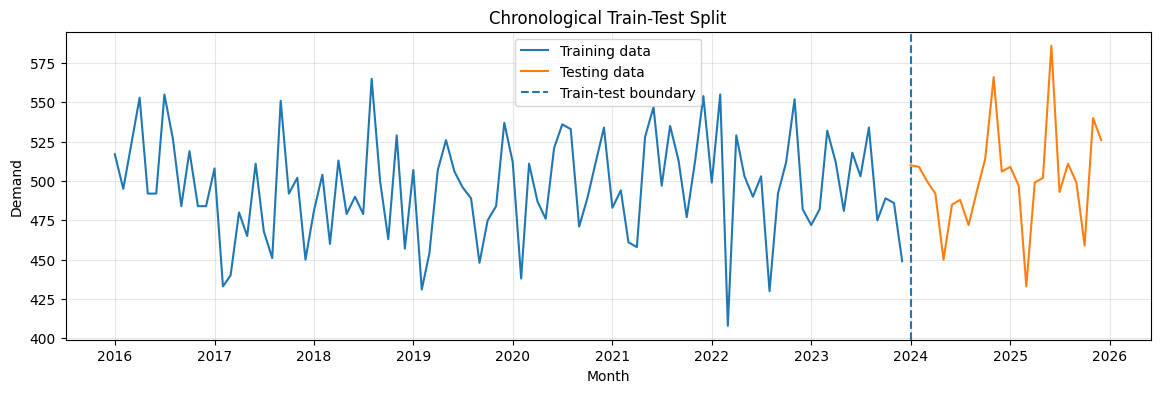

In [8]:
split = int(len(demand) * 0.80)
train, test = demand.iloc[:split], demand.iloc[split:]

print("Training observations:", len(train), "| Testing observations:", len(test))
print("Training:", train.index.min().date(), "to", train.index.max().date())
print("Testing:", test.index.min().date(), "to", test.index.max().date())

plt.figure(figsize=(14, 4))
plt.plot(train.index, train.values, label="Training data")
plt.plot(test.index, test.values, label="Testing data")
plt.axvline(test.index[0], linestyle="--", label="Train-test boundary")
plt.title("Chronological Train-Test Split")
plt.xlabel("Month"); plt.ylabel("Demand")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 9. Fit SES with statsmodels

`SimpleExpSmoothing` provides a standard SES implementation. We fit a model with a fixed alpha and another model where alpha is optimized using training data.

In [9]:
fixed_model = SimpleExpSmoothing(
    train, initialization_method="estimated"
).fit(smoothing_level=0.30, optimized=False)

optimized_model = SimpleExpSmoothing(
    train, initialization_method="estimated"
).fit(optimized=True)

print("Fixed alpha:", fixed_model.params["smoothing_level"])
print("Optimized alpha:", optimized_model.params["smoothing_level"])
print("Optimized initial level:", optimized_model.params.get("initial_level"))

Fixed alpha: 0.3
Optimized alpha: 1.4901161193847656e-08
Optimized initial level: 496.0833342365861


## 10. Forecast the test horizon

SES produces a flat point forecast across the horizon. Each test forecast is the final level estimated from the training observations.

In [ ]:
fixed_pred = fixed_model.forecast(len(test))
optimized_pred = optimized_model.forecast(len(test))

test_forecasts = pd.DataFrame({
    "Actual": test,
    "SES_Fixed_Alpha": np.asarray(fixed_pred),
    "SES_Optimized_Alpha": np.asarray(optimized_pred)
}, index=test.index)
display(test_forecasts.head(10))

## 11. Evaluate forecast performance

Metrics:
- **MAE:** average absolute error.
- **RMSE:** penalizes larger errors more heavily.
- **WMAPE:** total absolute error divided by total absolute actual demand.
- **MAPE:** average absolute percentage error; only meaningful here because the synthetic test actuals are non-zero.
- **Mean Bias:** average forecast minus actual; positive means over-forecasting.

$$
MAE = \\frac{1}{n}\\sum_{t=1}^{n}|Y_t-\\hat{Y}_t|
$$

$$
RMSE = \\sqrt{\\frac{1}{n}\\sum_{t=1}^{n}(Y_t-\\hat{Y}_t)^2}
$$

$$
WMAPE = \\frac{\\sum_{t=1}^{n}|Y_t-\\hat{Y}_t|}{\\sum_{t=1}^{n}|Y_t|}
$$

In [ ]:
def forecast_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    error = forecast - actual
    denom = np.sum(np.abs(actual))
    nonzero = actual != 0
    return {
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": np.sqrt(mean_squared_error(actual, forecast)),
        "WMAPE": np.sum(np.abs(error)) / denom if denom else np.nan,
        "MAPE (%)": np.mean(np.abs(error[nonzero] / actual[nonzero])) * 100 if nonzero.any() else np.nan,
        "Mean Bias": np.mean(error)
    }

metrics = pd.DataFrame({
    "SES Fixed Alpha": forecast_metrics(test, fixed_pred),
    "SES Optimized Alpha": forecast_metrics(test, optimized_pred)
}).T
display(metrics.sort_values("WMAPE"))

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training actual")
plt.plot(test.index, test.values, label="Test actual", marker="o")
plt.plot(test.index, fixed_pred, label="SES fixed alpha = 0.30", linewidth=2)
plt.plot(test.index, optimized_pred, label="SES optimized alpha", linewidth=2)
plt.title("SES Test Forecast Comparison")
plt.xlabel("Month"); plt.ylabel("Demand")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 12. Select alpha using a validation window

Use the last 20% of the training data as a validation set. The final test set remains untouched until final evaluation. For more robust selection, use rolling-origin validation across several forecast origins.

In [ ]:
inner_split = int(len(train) * 0.80)
sub_train, validation = train.iloc[:inner_split], train.iloc[inner_split:]
alpha_candidates = np.arange(0.05, 1.00, 0.05)
validation_rows = []

for a in alpha_candidates:
    model = SimpleExpSmoothing(
        sub_train, initialization_method="estimated"
    ).fit(smoothing_level=float(a), optimized=False)
    pred = model.forecast(len(validation))
    validation_rows.append({"alpha": a, **forecast_metrics(validation, pred)})

alpha_results = pd.DataFrame(validation_rows).sort_values("RMSE")
display(alpha_results.head(10))
best_alpha = float(alpha_results.iloc[0]["alpha"])
print("Best alpha on this validation window:", best_alpha)

## 13. Refit on all history and forecast the future

After selecting the model configuration, refit using all available history. SES carries the final estimated level forward, so its multi-step point forecast is constant.

In [ ]:
final_model = SimpleExpSmoothing(
    demand, initialization_method="estimated"
).fit(optimized=True)

horizon = 12
raw_future = final_model.forecast(horizon)
future_dates = pd.date_range(
    demand.index[-1] + pd.offsets.MonthBegin(1), periods=horizon, freq="MS"
)
future_forecast = pd.Series(
    np.asarray(raw_future), index=future_dates, name="SES_Forecast"
)
display(future_forecast.to_frame())
print("Final alpha:", round(float(final_model.params["smoothing_level"]), 4))
print("Forecast level:", round(float(future_forecast.iloc[0]), 2))

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(demand.index, demand.values, label="Historical demand", marker="o", markersize=3)
plt.plot(future_forecast.index, future_forecast.values, label="12-month SES forecast", marker="o")
plt.axvline(demand.index[-1], linestyle="--", label="Forecast origin")
plt.title("Simple Exponential Smoothing – Future Forecast")
plt.xlabel("Month"); plt.ylabel("Demand")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 14. Residual analysis

Residuals are actual values minus one-step-ahead fitted values:

$$
e_t = Y_t - \\hat{Y}_{t|t-1}
$$

A useful model should generally leave residuals without a systematic pattern. Inspect whether residuals are centred around zero and whether there is remaining trend or autocorrelation.

In [ ]:
residuals = (train - optimized_model.fittedvalues).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(residuals.index, residuals.values)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("SES Training Residuals")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Residual")
axes[0].grid(True, alpha=.3)

axes[1].hist(residuals.values, bins=20)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual"); axes[1].set_ylabel("Frequency")
axes[1].grid(True, alpha=.3)
plt.tight_layout(); plt.show()

print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

## 15. Advantages and limitations

### Advantages
- Simple and easy to understand.
- Uses only one smoothing parameter.
- Gives greater weight to recent observations.
- Computationally efficient.
- Useful as a baseline for stable-demand products.

### Limitations
- Does not explicitly model trend.
- Does not explicitly model seasonality.
- Produces a flat multi-step point forecast.
- High alpha can overreact to random noise.
- Low alpha can be slow to respond to genuine level changes.

## 16. Supply-chain application

Imagine a product whose monthly demand fluctuates around 500 units without a clear upward or downward trend or seasonal pattern. SES smooths random fluctuations and estimates the underlying demand level.

Possible uses include monthly replenishment planning, baseline demand estimation and benchmarking more complex models.

For products with clear trends, seasonality or intermittent demand, select a method that represents those patterns rather than forcing SES to fit them.

## 17. SES vs other exponential smoothing methods

| Method | Components | Suitable pattern |
|---|---|---|
| Simple Exponential Smoothing | Level | No clear trend or seasonality |
| Holt's Linear Trend | Level + trend | Trend, no seasonality |
| Holt-Winters | Level + trend + seasonality | Trend and seasonal pattern |

SES is the foundation for understanding more advanced exponential smoothing methods.

## 18. Key takeaway

**Simple Exponential Smoothing estimates the current level of a time series by combining the latest actual observation with the previous smoothed level.** Alpha controls the balance between responsiveness and stability.

SES is suitable when demand fluctuates around a relatively stable level without a clear trend or seasonal pattern.

## References
1. Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* – Simple exponential smoothing: https://otexts.robjhyndman.com/fpp3/exponential-smoothing.html
2. Statsmodels – `SimpleExpSmoothing`: https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.SimpleExpSmoothing.html
3. Statsmodels example – Exponential smoothing: https://www.statsmodels.org/stable/examples/notebooks/generated/exponential_smoothing.html
4. SAS/ETS User's Guide – Equations for smoothing models: https://documentation.sas.com/api/docsets/etsug/15.2/content/tffordet.pdf

---